# Kaggle Competition — RiskScore Prediction

### Цель: построить модель линейной регрессии для предсказания RiskScore и оценить качество по MSE.

1. Импорт библиотек и загрузка данных

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("ex.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

display(train.head())
display(test.head())

Train: (11017, 35)
Test: (5000, 35)
Sample submission: (5000, 2)


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


,ID,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,...,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio
0,0,1979-01-03,49,207095,850,14458,60,Single,0,Rent,...,0.883232,6,Employed,High School,23,10626,0.104458,0.125350,325.532336,0.040650
1,1,2006-04-10,28,64653,674,65491,48,Single,2,Own,...,0.791928,3,Employed,High School,3,299024,0.233491,0.260561,2210.247757,0.454410
2,2,2013-11-28,41,300000,768,16811,60,Single,1,Own,...,0.805826,3,Employed,High School,19,6979,0.147811,0.154571,403.977431,0.034919
3,3,1995-08-24,50,300000,850,48737,36,Divorced,0,Mortgage,...,0.829294,3,Self-Employed,Bachelor,26,8438,0.118737,0.099712,1571.946906,0.085558
4,4,1980-06-15,35,300000,672,51916,60,Single,6,Mortgage,...,0.735013,7,Employed,Associate,12,436216,0.230916,0.237727,1486.675235,0.063707


2. Проверка и очистка целевой переменной

In [142]:
print("Пропуски в RiskScore:", train["RiskScore"].isna().sum())
print("Маркер -9999999:", (train["RiskScore"] == -9999999).sum())
print("Маркер 10000000:", (train["RiskScore"] == 10000000).sum())

train_model = train[
    train["RiskScore"].notna()
    & train["RiskScore"].between(0, 100)
].copy()

print("Размер исходного train:", train.shape)
print("Размер train_model:", train_model.shape)
display(train_model["RiskScore"].describe())

Пропуски в RiskScore: 530
Маркер -9999999: 121
Маркер 10000000: 94
Размер исходного train: (11017, 35)
Размер train_model: (10272, 35)


count    10272.000000
mean        48.358094
std         17.241456
min         14.841417
25%         32.722756
50%         44.195792
75%         65.124190
max         97.597249
Name: RiskScore, dtype: float64

3. Разделение на обучающую и проверочную выборки

In [143]:
X = train_model.drop(columns=["RiskScore"])
y = train_model["RiskScore"].astype(float)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (8217, 34)
X_val: (2055, 34)


4. Подготовка признаков

In [144]:
def add_date_features(df):
    df = df.copy()
    date = pd.to_datetime(df["ApplicationDate"], errors="coerce")
    df["ApplicationYear"] = date.dt.year
    df["ApplicationMonth"] = date.dt.month
    df["ApplicationDay"] = date.dt.day
    return df.drop(columns=["ApplicationDate"])

X_train = add_date_features(X_train)
X_val = add_date_features(X_val)

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Числовых признаков:", len(numeric_features))
print("Категориальные признаки:", categorical_features)

Числовых признаков: 31
Категориальные признаки: ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']


Заполнение пропусков

In [145]:
numeric_medians = X_train[numeric_features].median()
categorical_modes = X_train[categorical_features].mode().iloc[0]

X_train[numeric_features] = X_train[numeric_features].fillna(numeric_medians)
X_val[numeric_features] = X_val[numeric_features].fillna(numeric_medians)

X_train[categorical_features] = X_train[categorical_features].fillna(categorical_modes)
X_val[categorical_features] = X_val[categorical_features].fillna(categorical_modes)

print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_val:", X_val.isna().sum().sum())

Пропуски в X_train: 0
Пропуски в X_val: 0


One-Hot Encoding

In [146]:
X_train = pd.get_dummies(X_train, columns=categorical_features, dtype=int)
X_val = pd.get_dummies(X_val, columns=categorical_features, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

print("Размер X_train:", X_train.shape)
print("Размер X_val:", X_val.shape)

Размер X_train: (8217, 52)
Размер X_val: (2055, 52)


Доп рефакторинг

In [152]:

# Создаем дополнительные признаки
for frame in [X_train, X_val]:

    # Нелинейное влияние дохода
    frame["Log_MonthlyIncome"] = np.log1p(
        frame["MonthlyIncome"].clip(lower=0)
    )

    # Нелинейное влияние кредитного рейтинга
    frame["CreditScore_sq"] = frame["CreditScore"] ** 2

    # Нелинейное влияние активов
    frame["Log_TotalAssets"] = np.log1p(
        frame["TotalAssets"].clip(lower=0)
    )

    # Нелинейное влияние базовой процентной ставки
    frame["BaseInterestRate_sq"] = (
        frame["BaseInterestRate"] ** 2
    )

    # Нелинейное влияние долговой нагрузки
    frame["Log_TotalDebtToIncomeRatio"] = np.log1p(
        frame["TotalDebtToIncomeRatio"].clip(lower=0)
    )

print("Количество признаков:", X_train.shape[1])
print("Train:", X_train.shape)
print("Validation:", X_val.shape)


Количество признаков: 59
Train: (8217, 59)
Validation: (2055, 59)


Z-score нормализация

In [153]:
z_mean = X_train.mean()
z_std = X_train.std(ddof=0).replace(0, 1)

X_train_z = ((X_train - z_mean) / z_std).astype(float)
X_val_z = ((X_val - z_mean) / z_std).astype(float)

print("Пропуски после нормализации:", X_train_z.isna().sum().sum())
print("Размеры:", X_train_z.shape, X_val_z.shape)

Пропуски после нормализации: 0
Размеры: (8217, 59) (2055, 59)


5. Собственная линейная регрессия

In [154]:
class MyLinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        X_bias = np.c_[np.ones(X.shape[0]), X]
        self.weights = np.linalg.pinv(X_bias) @ y
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        return X_bias @ self.weights

model = MyLinearRegression()
model.fit(X_train_z, y_train)

y_pred = model.predict(X_val_z)

Базовые метрики

In [155]:
mse = mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2:  {r2:.4f}")

MSE: 37.7688
MAE: 4.7628
R2:  0.8737


6. Анализ ошибок модели

In [124]:
errors = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_pred
})
errors["Error"] = errors["Actual"] - errors["Predicted"]
errors["AbsoluteError"] = errors["Error"].abs()
errors["SquaredError"] = errors["Error"] ** 2

print("Средняя ошибка:", errors["Error"].mean())
print("Медианная абсолютная ошибка:", errors["AbsoluteError"].median())
print("95-й процентиль абсолютной ошибки:", errors["AbsoluteError"].quantile(0.95))

display(errors.sort_values("AbsoluteError", ascending=False).head(15))

Средняя ошибка: -0.18258794820364022
Медианная абсолютная ошибка: 5.005357838917881
95-й процентиль абсолютной ошибки: 13.829159581130037


,Actual,Predicted,Error,AbsoluteError,SquaredError
6,35.289893,-3.166450,38.456343,38.456343,1478.890337
394,45.041600,73.232656,-28.191055,28.191055,794.735597
1912,47.595715,72.708507,-25.112792,25.112792,630.652334
1757,40.996571,63.750820,-22.754249,22.754249,517.755852
1031,21.709946,43.512466,-21.802520,21.802520,475.349893
1893,82.278974,60.998833,21.280141,21.280141,452.844418
1005,33.400744,54.405431,-21.004687,21.004687,441.196878
1999,81.000457,60.316365,20.684092,20.684092,427.831642
932,79.202508,58.642401,20.560107,20.560107,422.717985
1121,20.483928,40.833087,-20.349159,20.349159,414.088270


Фактические и предсказанные значения

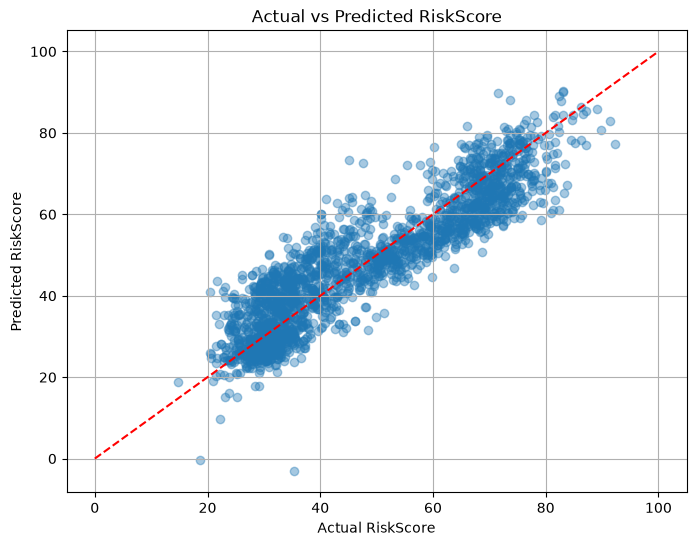

In [125]:
plt.figure(figsize=(8, 6))
plt.scatter(errors["Actual"], errors["Predicted"], alpha=0.4)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual RiskScore")
plt.ylabel("Predicted RiskScore")
plt.title("Actual vs Predicted RiskScore")
plt.grid()
plt.show()

График остатков

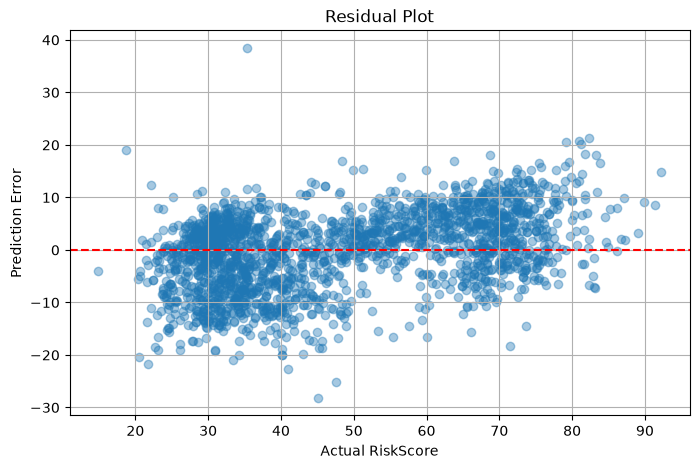

In [126]:
plt.figure(figsize=(8, 5))
plt.scatter(errors["Actual"], errors["Error"], alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual RiskScore")
plt.ylabel("Prediction Error")
plt.title("Residual Plot")
plt.grid()
plt.show()

MSE по диапазонам фактического RiskScore

In [127]:
errors["ScoreGroup"] = pd.cut(
    errors["Actual"],
    bins=[0, 35, 65, 100],
    labels=["Низкий (0–35)", "Средний (35–65)", "Высокий (65–100)"],
    include_lowest=True
)

group_errors = errors.groupby("ScoreGroup", observed=False).agg(
    Count=("SquaredError", "count"),
    MSE=("SquaredError", "mean"),
    MeanActual=("Actual", "mean"),
    MeanPredicted=("Predicted", "mean")
)

display(group_errors)

,Count,MSE,MeanActual,MeanPredicted
ScoreGroup,,,,
Низкий (0–35),711,52.068240,30.008214,32.687375
Средний (35–65),829,53.595731,48.349628,48.862010
Высокий (65–100),515,56.731640,71.856773,68.061763


Анализ ошибок по группам целевой переменной показал, что модель имеет тенденцию завышать низкие значения RiskScore и занижать высокие. Наиболее высокая ошибка наблюдается в группе высоких значений (MSE = 56.73), а наименьшая — в группе низких значений (MSE = 52.07). Это может свидетельствовать о недостаточной способности линейной модели описывать зависимости на краях диапазона целевой переменной.

### 7. Выводы и дальнейшие эксперименты

Первый эксперимент - уберем дублирующие значения

In [128]:
# Признаки, которые временно исключим
features_to_remove = [
    "MonthlyIncome",
    "NetWorth",
    "Experience",
    "InterestRate"
]

# Удаляем их из обучающей и проверочной выборок
X_train_reduced = X_train_z.drop(columns=features_to_remove)
X_val_reduced = X_val_z.drop(columns=features_to_remove)

print("Исходное количество признаков:", X_train_z.shape[1])
print("Количество признаков после удаления:", X_train_reduced.shape[1])

Исходное количество признаков: 52
Количество признаков после удаления: 48


In [129]:
model_reduced = MyLinearRegression()

model_reduced.fit(X_train_reduced, y_train)

y_pred_reduced = model_reduced.predict(X_val_reduced)

mse_reduced = mean_squared_error(y_val, y_pred_reduced)

print("MSE после удаления признаков:", mse_reduced)

MSE после удаления признаков: 57.776504102570186


In [130]:
print("Базовая модель MSE:", mean_squared_error(y_val, y_pred))
print("Модель без 4 признаков MSE:", mse_reduced)

Базовая модель MSE: 53.85312578435701
Модель без 4 признаков MSE: 57.776504102570186


Окей, совместное удаление дает 57 против 53. Тогда по одному?

In [131]:
features_to_test = [
    "MonthlyIncome",
    "NetWorth",
    "Experience",
    "InterestRate"
]

for feature in features_to_test:
    X_train_temp = X_train_z.drop(columns=[feature])
    X_val_temp = X_val_z.drop(columns=[feature])

    model_temp = MyLinearRegression()
    model_temp.fit(X_train_temp, y_train)

    pred_temp = model_temp.predict(X_val_temp)
    mse_temp = mean_squared_error(y_val, pred_temp)

    print(f"Без {feature}: MSE = {mse_temp:.4f}")

Без MonthlyIncome: MSE = 55.1896
Без NetWorth: MSE = 53.8165
Без Experience: MSE = 53.8628
Без InterestRate: MSE = 56.2726


А два?

In [132]:
X_train_temp = X_train_z.drop(
    columns=["NetWorth", "Experience"]
)
X_val_temp = X_val_z.drop(
    columns=["NetWorth", "Experience"]
)

model_temp = MyLinearRegression()
model_temp.fit(X_train_temp, y_train)

pred_temp = model_temp.predict(X_val_temp)

print(
    "MSE без NetWorth и Experience:",
    mean_squared_error(y_val, pred_temp)
)

MSE без NetWorth и Experience: 53.874222606832916


Удаление ничего не дало, попробуем исследовать качество

In [133]:
important_features = [
    "CreditScore",
    "BaseInterestRate",
    "InterestRate"
]

display(
    train_model[important_features + ["RiskScore"]].describe().T
)

,count,mean,std,min,25%,50%,75%,max
CreditScore,9787.0,677.911515,175.374136,300.000000,550.000000,722.000000,850.000000,850.000000
BaseInterestRate,9787.0,0.200502,0.094560,0.052494,0.119862,0.182072,0.265098,0.722497
InterestRate,10272.0,0.200193,0.096586,0.046445,0.119542,0.180826,0.264993,0.833647
RiskScore,10272.0,48.358094,17.241456,14.841417,32.722756,44.195792,65.124190,97.597249


In [134]:
missing_check = train_model[
    ["CreditScore", "BaseInterestRate"]
].isna()

print("Количество пропусков:")
print(missing_check.sum())

print("\nСовпадение пропусков:")
print(missing_check.value_counts())

Количество пропусков:
CreditScore         485
BaseInterestRate    485
dtype: int64

Совпадение пропусков:
CreditScore  BaseInterestRate
False        False               9787
True         True                 485
Name: count, dtype: int64


Опа, попуски CreditScore и BaseInterestRate совпадают!!!

Добавим индикаторы пропусков

In [150]:
# Индикаторы исходных пропусков
for df in [X_train, X_val]:
    df["CreditScore_missing"] = df["CreditScore"].isna().astype(int)
    df["BaseInterestRate_missing"] = df["BaseInterestRate"].isna().astype(int)

In [151]:
model_missing = MyLinearRegression()

model_missing.fit(X_train_z, y_train)

y_pred_missing = model_missing.predict(X_val_z)

mse_missing = mean_squared_error(y_val, y_pred_missing)

print("MSE с индикаторами пропусков:", mse_missing)

MSE с индикаторами пропусков: 53.85312578435701
